Folie 36 Hausaufgabe

In [19]:
import pandas as pd
from itertools import combinations

# Liste aller möglichen Karten
cards = ['2H', '3H', '4H', '5H', '6H', '7H', '8H', '9H', 'TH', 'JH', 'QH', 'KH', 'AH',
         '2S', '3S', '4S', '5S', '6S', '7S', '8S', '9S', 'TS', 'JS', 'QS', 'KS', 'AS',
         '2C', '3C', '4C', '5C', '6C', '7C', '8C', '9C', 'TC', 'JC', 'QC', 'KC', 'AC',
         '2D', '3D', '4D', '5D', '6D', '7D', '8D', '9D', 'TD', 'JD', 'QD', 'KD', 'AD']

start_hands = list(combinations(cards, 2))  # Kombinationen aller Starthände

counts = {}
for i in start_hands:
    if i[0][0] == i[1][0]:
        # Paar
        key = 'Pair of ' + i[0][0] + ':'
    elif i[0][1] == i[1][1]:
        # Gleiche Farbe
        key = i[0][1] + ' suited:'
    elif i[0][0] == 'K' and i[1][0] == 'A' or i[0][0] == 'A' and i[1][0] == 'K':
        # Kombination von zwei Kartentypen, z.B. König und Ass
        key = 'King and Ace:'
    else:
        # Kein Paar und unterschiedliche Farbe
        key = 'Nothing:'
    if key in counts:
        counts[key] += 1
    else:
        counts[key] = 1

probabilities = {}
for key, value in counts.items():
    probabilities[key] = str(round(value / len(start_hands) * 100, 3)) + " %"

print('Gesamtanzahl an möglichen Starthänden: ', sum(counts.values()))
print()
counts_series = pd.Series(counts)
counts_series = counts_series.sort_values()
print(counts_series)
print()
probabilities_series = pd.Series(probabilities)
probabilities_series = probabilities_series.sort_values()
print(probabilities_series)

Gesamtanzahl an möglichen Starthänden:  1326

Pair of 9:         6
Pair of 2:         6
Pair of 3:         6
Pair of 4:         6
Pair of 5:         6
Pair of 6:         6
Pair of 7:         6
Pair of 8:         6
Pair of A:         6
Pair of T:         6
Pair of J:         6
Pair of Q:         6
Pair of K:         6
King and Ace:     12
S suited:         78
H suited:         78
C suited:         78
D suited:         78
Nothing:         924
dtype: int64

Pair of 9:        0.452 %
Pair of 2:        0.452 %
Pair of 3:        0.452 %
Pair of 4:        0.452 %
Pair of 5:        0.452 %
Pair of 6:        0.452 %
Pair of 7:        0.452 %
Pair of 8:        0.452 %
Pair of A:        0.452 %
Pair of T:        0.452 %
Pair of J:        0.452 %
Pair of Q:        0.452 %
Pair of K:        0.452 %
King and Ace:     0.905 %
S suited:         5.882 %
H suited:         5.882 %
C suited:         5.882 %
D suited:         5.882 %
Nothing:         69.683 %
dtype: object


Folie 48: Gleichverteilte Stetige Zufallsvariablen

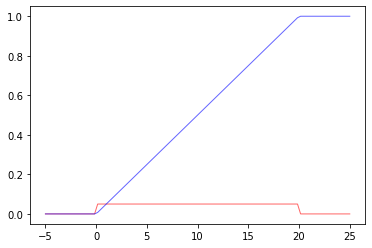

In [1]:
import numpy as np
from scipy.stats import uniform
import matplotlib.pyplot as plt
x = np.linspace(-5.00,25.00, 100)
plt.plot(x, uniform(0,20).pdf(x),'r-', lw=1, alpha=0.6, label='uniform pdf')
plt.plot(x, uniform(0,20).cdf(x),'b-', lw=1, alpha=0.6, label='uniform pdf')

Folie 51: Abweichung vom Sollwert

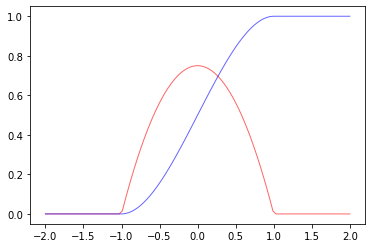

In [4]:
from scipy.stats import rv_continuous
class quality_deviation_gen(rv_continuous):
     def _pdf(self, x):
            new_x = 3/4*(1-x**2)
            new_x =new_x*(new_x>0)
            return new_x 
qd = quality_deviation_gen()

x = np.linspace(-2.00,2.00, 100)
plt.plot(x, qd.pdf(x),'r-', lw=1, alpha=0.6, label='pdf')
plt.plot(x, qd.cdf(x),'b-', lw=1, alpha=0.6, label='cdf')

Folie 58

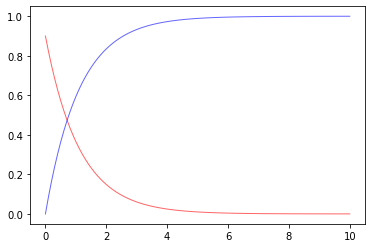

In [36]:
from scipy.stats import expon
x = np.linspace(0,10, 100)
l = 0.9
plt.plot(x, expon.pdf(x, scale = 1/l),'r-', lw=1, alpha=0.6, label='pdf')
plt.plot(x, expon.cdf(x,scale = 1/l),'b-', lw=1, alpha=0.6, label='cdf')

Folie 59

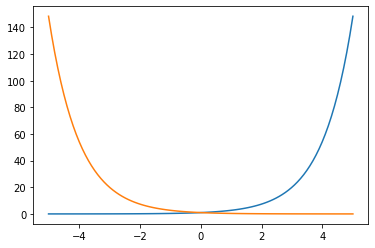

In [11]:
# Weg zur Normalverteilung
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(-5,5,100)
y =np.e**x
plt.plot(x,y)
y =np.e**-x
plt.plot(x,y)

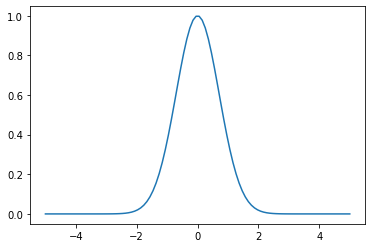

In [12]:
y =np.e**-(x)**2
plt.plot(x,y)

In [23]:
import numpy as np
def normal(x, mu, sigma):
    return (1/np.sqrt(2*np.pi*sigma))*np.e**((-(x-mu)**2)/(2*sigma**2))

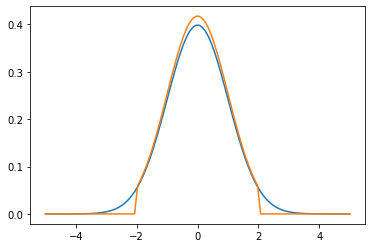

In [34]:
import matplotlib.pyplot as plt
x = np.linspace(-5,5,100)
y = normal(x, 0, 1)
plt.plot(x,y)

from scipy.stats import truncnorm
a,b = (-2,2)
plt.plot(x, truncnorm.pdf(x, a, b), label='truncnorm pdf')

Folie 62

In [44]:
from scipy.stats import norm
1-norm.cdf(82, loc = 83, scale=5)

0.579259709439103

Folie 63: Stuhlgröße in der FH

87.20810616786457

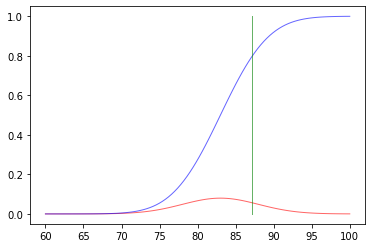

In [38]:
from scipy.stats import norm
x = np.linspace(60,100, 100)
plt.plot(x, norm.pdf(x, loc = 83, scale=5),'r-', lw=1, alpha=0.6, label='pdf')
plt.plot(x, norm.cdf(x, loc = 83, scale=5),'b-', lw=1, alpha=0.6, label='cdf')
y_08 = np.linspace(0,1,100)
#  Percent point function (inverse of cdf )
x_08 = np.ones_like(y_08) * norm.ppf(0.8, loc = 83, scale=5)
plt.plot(x_08, y_08,'g-', lw=1, alpha=0.6, label='cdf')
norm.ppf(0.8, loc = 83, scale=5)

Folie 64: Stühle und Tische

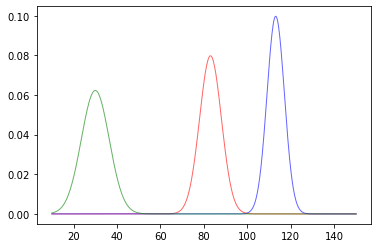

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
x = np.linspace(10,150, 500)
plt.plot(x, norm.pdf(x, loc = 83, scale=5),'r-', lw=1, alpha=0.6, label='chairs')
plt.plot(x, norm.pdf(x, loc = 113, scale=4),'b-', lw=1, alpha=0.6, label='table')
plt.plot(x, norm.pdf(x, loc = 30, scale=np.sqrt(41)),'g-', lw=1, alpha=0.6, label='table_chair')

Folie 66

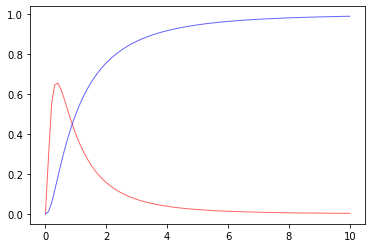

In [45]:
from scipy.stats import lognorm
x = np.linspace(0,10, 100)
l = 0.9
plt.plot(x, lognorm.pdf(x, s=1),'r-', lw=1, alpha=0.6, label='pdf')
plt.plot(x, lognorm.cdf(x, s=1),'b-', lw=1, alpha=0.6, label='cdf')

Folie 73

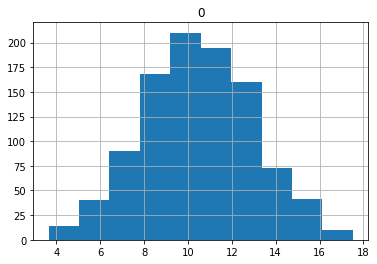

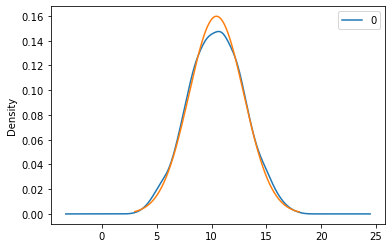

In [14]:
# grenzwertsatz
import numpy as np
import pandas as pd
from scipy.stats import uniform, norm
import matplotlib.pyplot as plt

dice = uniform(1,5)
n = 3
distribution = np.zeros(1000)
for i in range(n):
    x = np.random.random(1000)
    distribution += dice.ppf(x)
pd.DataFrame(distribution).hist()
pd.DataFrame(distribution).plot.kde()

a = np.linspace(n,6*n,1000)
plt.plot(a, norm.pdf(a, loc=distribution.mean(),scale=distribution.std()))

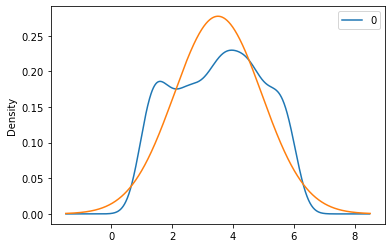

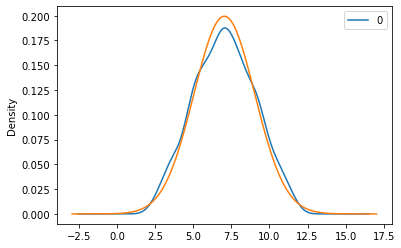

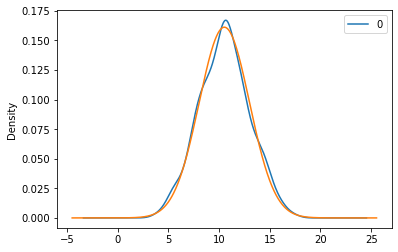

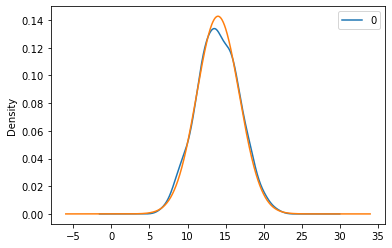

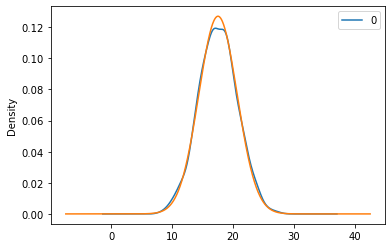

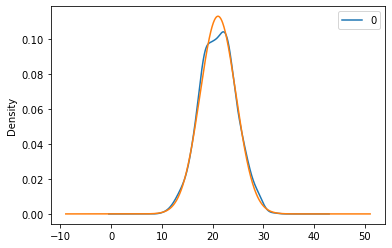

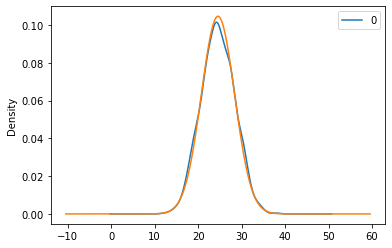

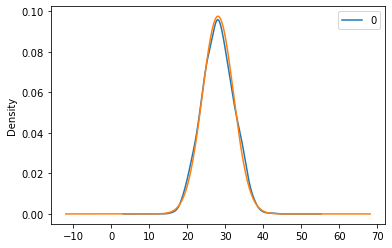

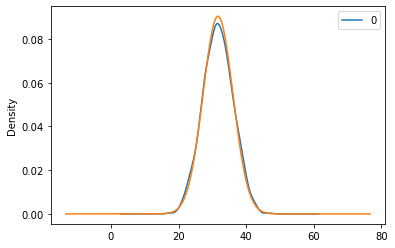

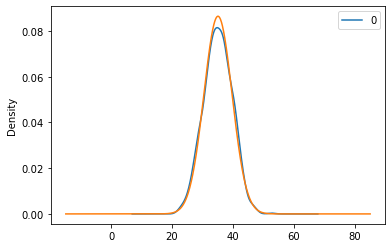

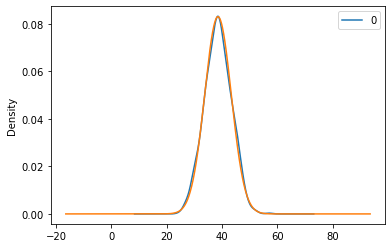

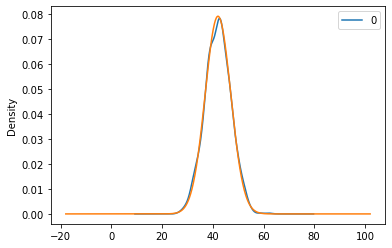

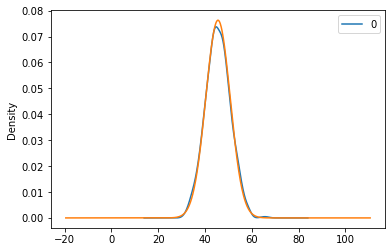

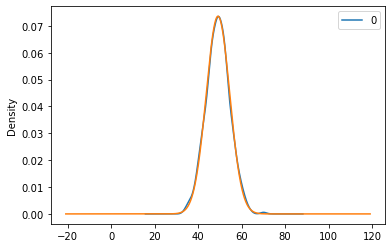

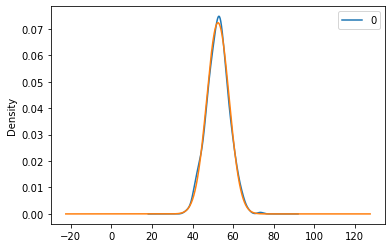

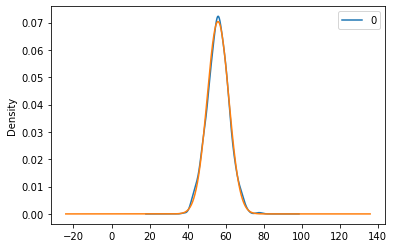

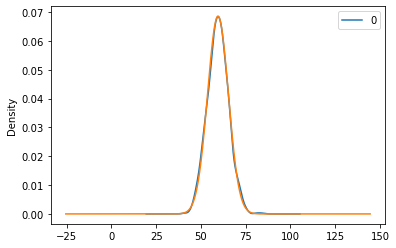

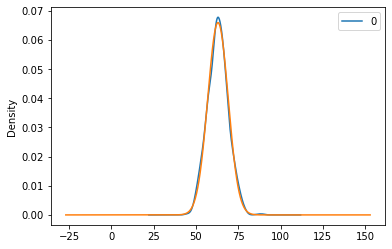

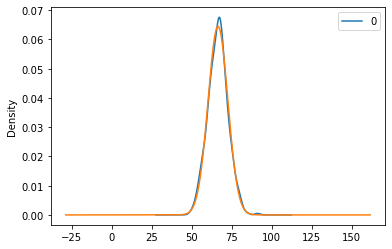

In [87]:
def distribution_sum(distribution):
    sum_distribution = np.zeros(1000)
    n = 1
    while True:
        x = np.random.random(1000)
        sum_distribution += distribution.ppf(x)
        
        pd.DataFrame(sum_distribution).plot(kind="kde")#,ax=ax)
        a = np.linspace(sum_distribution.mean()-n*5,sum_distribution.mean()+n*5,1000)
        plt.plot(a, norm.pdf(a, loc=sum_distribution.mean(),scale=sum_distribution.std()))
        n = yield

dice = uniform(1,5)
distr = distribution_sum(dice)
next(distr)
for i in range(2, 20):
    distr.send(i)


Folie 77 Linearer Kongruenzgenerator

In [16]:
def LCG(a, c, m, seed):     
    xi = seed
    while True:
        xf = (a * xi + c) % m
        xi = xf
        yield xf

def random_sample(n, interval, seed = 20200420162000, integer = True):
    lower, upper = interval[0], interval[1]
    sample = []
    m = 2 ** 32
    glibc = LCG(1103515245, 12345, m, seed)
    for i in range(n):
        observation = (upper - lower) * (next(glibc) / m) + lower
        if integer:
            observation = int(observation)     
        sample.append(observation)
    return sample

0.49937832368861884


array([[<AxesSubplot:title={'center':'0'}>]], dtype=object)

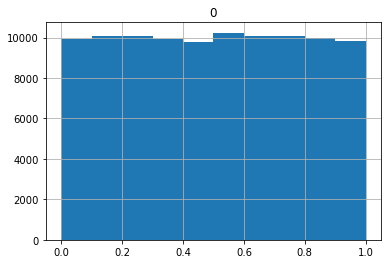

In [18]:
import datetime
sample = random_sample(100000, [0, 1], seed = datetime.datetime.now().microsecond, integer = False)
print(sum(sample)/len(sample))

pd.DataFrame(sample).hist()

array([[<AxesSubplot:title={'center':'0'}>]], dtype=object)

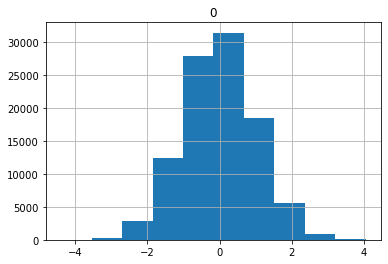

In [95]:
#normal verteilte samples
from scipy.stats import norm
import pandas as pd
#sample = random_sample(1000, [0, 1], seed = datetime.datetime.now().microsecond, integer = False)
sample_norm = norm.ppf(sample, loc = 0, scale=1)
pd.DataFrame(sample_norm).hist()